**CO2 EMISSIONS PROJECT**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

vehicle_df = pd.read_csv(
    '/content/drive/MyDrive/CO2 Emissions_Canada.csv'
)

vehicle_df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [3]:
import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ipywidgets import interact, IntSlider
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [4]:
# The notebook uses mean squared error for regression evaluation.

In [5]:
# Keep axis labels readable in the plots.
matplotlib.rc("xtick", labelsize=12)
matplotlib.rc("ytick", labelsize=12)

In [6]:
all_columns = [
    "Make", "Model", "Vehicle Class", "Engine Size(L)", "Cylinders",
    "Transmission", "Fuel Type", "Fuel Consumption City (L/100 km)",
    "Fuel Consumption Hwy (L/100 km)", "Fuel Consumption Comb (L/100 km)",
    "Fuel Consumption Comb (mpg)", "CO2 Emissions(g/km)",
]

numeric_columns = [
    "Engine Size(L)",
    "Cylinders",
    "Fuel Consumption City (L/100 km)",
    "Fuel Consumption Hwy (L/100 km)",
    "Fuel Consumption Comb (L/100 km)",
    "Fuel Consumption Comb (mpg)",
]

categorical_columns = [
    "Make",
    "Model",
    "Vehicle Class",
    "Transmission",
    "Fuel Type",
]

target_column = "CO2 Emissions(g/km)"


In [7]:
input_data = vehicle_df.drop(columns=[target_column])

In [8]:
emission_values = vehicle_df[target_column]

In [10]:
# Baseline: predict the mean emission value

In [11]:
# A simple baseline predicts the average emission value for every record.
baseline_prediction = emission_values.mean()
baseline_prediction

np.float64(250.58469871360867)

In [12]:
baseline_variance = np.var(emission_values)
print("Variance of the target values:", baseline_variance)

Variance of the target values: 3423.270043460344


In [13]:
print('Linear regression with one numerical feature')

Linear regression with one numerical feature


In [14]:
@interact(feature_index=IntSlider(min=0, max=5, step=1, value=0))
def plot_single_feature_model(feature_index):
    chosen_column = numeric_columns[feature_index]
    feature_values = vehicle_df[[chosen_column]].to_numpy()
    observed_emissions = emission_values.to_numpy()

    single_feature_model = LinearRegression()
    single_feature_model.fit(feature_values, observed_emissions)
    estimated_emissions = single_feature_model.predict(feature_values)

    # Sort by the chosen feature so the fitted line is easier to read.
    order = np.argsort(feature_values[:, 0])
    plt.figure(figsize=(8, 5))
    plt.scatter(feature_values[:, 0], observed_emissions, label="Observed values", alpha=0.55)
    plt.plot(
        feature_values[order, 0],
        estimated_emissions[order],
        "r-",
        label="Regression estimate",
    )
    plt.xlabel(chosen_column, fontsize=12)
    plt.ylabel(target_column, fontsize=10)
    plt.legend()
    plt.tight_layout()
    plt.show()

    error = mean_squared_error(observed_emissions, estimated_emissions)
    print("Mean squared error:", error)


interactive(children=(IntSlider(value=0, description='feature_index', max=5), Output()), _dom_classes=('widget…

In [15]:
print('Linear regression using several numerical features')

Linear regression using several numerical features


In [16]:
def compare_numeric_feature_sets(feature_indices):
    if not feature_indices:
        print("Select at least one feature.")
        return

    if any(index < 0 or index >= len(numeric_columns) for index in feature_indices):
        print("One or more feature indices are outside the available range.")
        return

    chosen_columns = [numeric_columns[index] for index in feature_indices]
    selected_values = vehicle_df[chosen_columns].to_numpy()
    observed_emissions = emission_values.to_numpy()

    numeric_model = LinearRegression()
    numeric_model.fit(selected_values, observed_emissions)
    estimated_emissions = numeric_model.predict(selected_values)

    for column_position, column_name in enumerate(chosen_columns):
        plt.figure(figsize=(8, 5))
        plt.scatter(
            selected_values[:, column_position],
            observed_emissions,
            label="Observed values",
            alpha=0.5,
        )
        plt.scatter(
            selected_values[:, column_position],
            estimated_emissions,
            label="Model estimates",
            alpha=0.5,
            color="red",
        )
        plt.xlabel(column_name, fontsize=12)
        plt.ylabel(target_column, fontsize=12)
        plt.legend()
        plt.tight_layout()
        plt.show()

    print("Mean squared error:", mean_squared_error(observed_emissions, estimated_emissions))
    print("Model coefficients:", numeric_model.coef_)
    print("Model intercept:", numeric_model.intercept_)


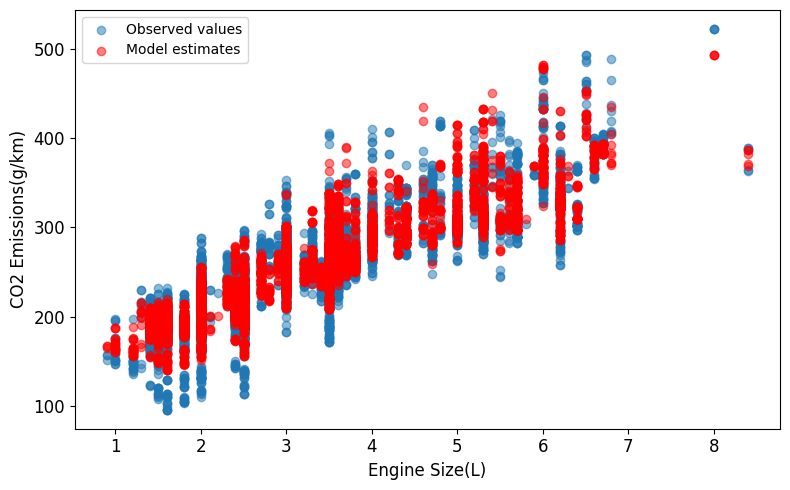

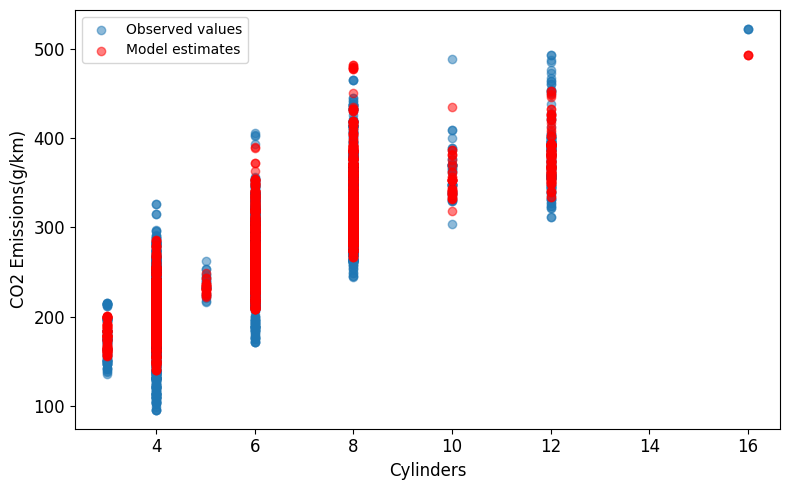

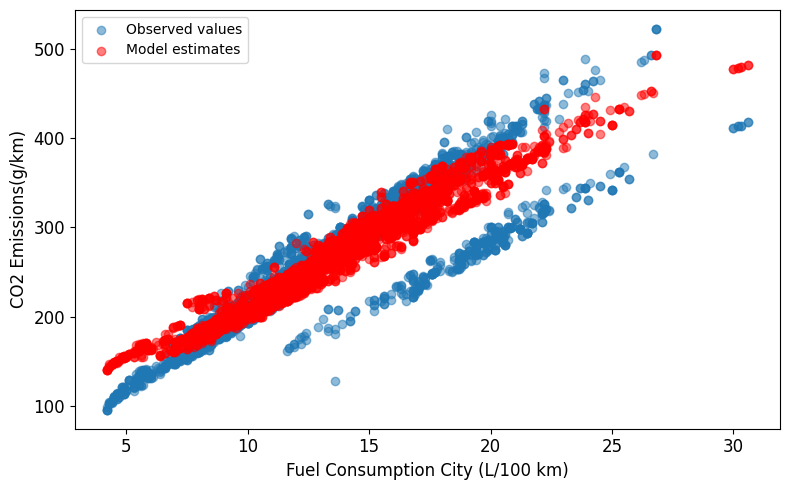

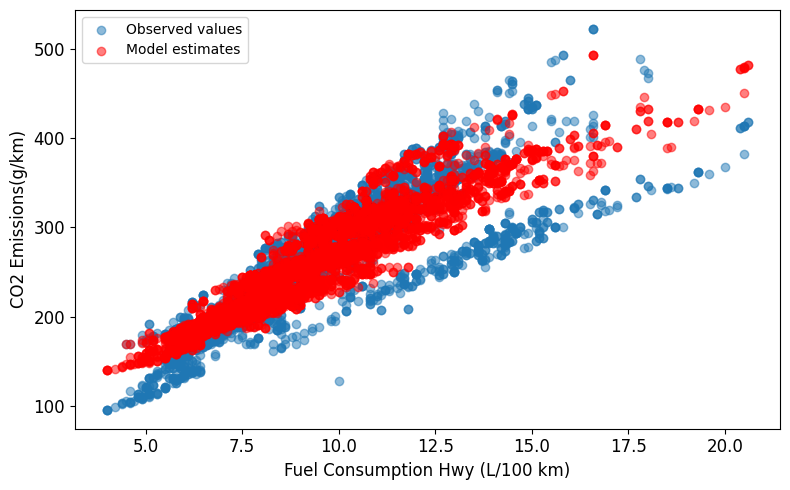

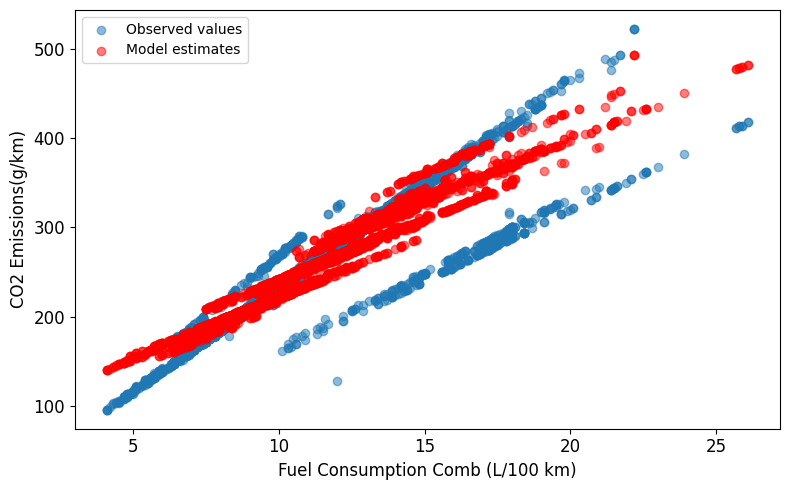

Mean squared error: 413.49651404221976
Model coefficients: [ 5.5089519   6.54212984  1.22122447  1.43498113 10.68921137]
Model intercept: 50.81790094056626


In [17]:
compare_numeric_feature_sets([0, 1, 2, 3, 4])

For categorical variables without a natural order, one-hot encoding is generally appropriate. Label encoding is more suitable when category values genuinely represent an order, provided the encoding reflects that order.**bold text**

Prepare the preprocessing and modelling **tools**

In [18]:
# Split the data before fitting the preprocessing and regression steps.

In [19]:
train_inputs, test_inputs, train_targets, test_targets = train_test_split(
    input_data,
    emission_values,
    test_size=0.2,
    random_state=42,
)

numeric_preparation = Pipeline(
    steps=[("scale", StandardScaler())]
)

categorical_preparation = Pipeline(
    steps=[("encode", OneHotEncoder(handle_unknown="ignore"))]
)

feature_preparation = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preparation, numeric_columns),
        ("categorical", categorical_preparation, categorical_columns),
    ]
)

emissions_pipeline = Pipeline(
    steps=[
        ("preparation", feature_preparation),
        ("regression", LinearRegression()),
    ]
)

# Fit on the training portion, then evaluate on records held out from training.
emissions_pipeline.fit(train_inputs, train_targets)
test_estimates = emissions_pipeline.predict(test_inputs)

print("MAE:", mean_absolute_error(test_targets, test_estimates))
print("MSE:", mean_squared_error(test_targets, test_estimates))
print("R²:", r2_score(test_targets, test_estimates))

# Save the fitted pipeline so it can be reused for later predictions.
joblib.dump(emissions_pipeline, "co2_emissions_pipeline.pkl")
emissions_pipeline = joblib.load("co2_emissions_pipeline.pkl")


MAE: 3.2430235745041838
MSE: 29.993701242946667
R²: 0.9912799563359063


Regression metrics are used because the target is continuous, not a class **label**

In [21]:
example_vehicle = pd.DataFrame(
    {
        "Make": ["BMW"],
        "Model": ["328i"],
        "Vehicle Class": ["COMPACT"],
        "Engine Size(L)": [2],
        "Cylinders": [4],
        "Transmission": ["A8"],
        "Fuel Type": ["Z"],
        "Fuel Consumption City (L/100 km)": [10],
        "Fuel Consumption Hwy (L/100 km)": [6.5],
        "Fuel Consumption Comb (L/100 km)": [8.4],
        "Fuel Consumption Comb (mpg)": [34],
    }
)

example_prediction = emissions_pipeline.predict(example_vehicle)
print("Predicted CO2 emissions (g/km):", example_prediction[0])

Predicted CO2 emissions (g/km): 190.14939450047638
